[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB12_brain_wiring.ipynb)

# Day 2 · Chapter 5 · Notebook 12 — The brain's wiring

The slides introduced the connectome as a network: hubs, short connections, modules, a small world, gradients. Here we
see these properties on the human connectome that our models use (100 regions, HCP), and then ask the question that
matters for modelling: **which property of the wiring does a model need to reproduce FC?** The last section prepares
the myelin map used in NB13b.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
# Load the human connectome, the measured FC and the region positions
import networkx as nx
from src import connectome, wholebrain
sc, fc, labels = connectome.load_hcp(weights="counts", normalize=False)      # fibre counts, empirical group FC
xyz = np.loadtxt("../data/connectome/centroids_ctx_schaefer_100.csv", delimiter=",", comments="#")   # region centres (mm)
net = np.array([l.split("_")[2] for l in labels])                 # resting-state network of each region (Yeo et al. 2011)
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
NETCOL = {n: f"C{k}" for k, n in enumerate(NETS)}
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]           # 1 = same pattern as the measured FC

def brain(ax, values, cmap="viridis", edges=None, title="", size=60, **kw):
    # view from above: x = left-right, y = back-front
    if edges is not None:
        for i, j in zip(*np.where(np.triu(edges))):
            ax.plot(xyz[[i, j], 0], xyz[[i, j], 1], c="0.6", lw=0.5, zorder=0)
    sc_ = ax.scatter(xyz[:, 0], xyz[:, 1], c=values, cmap=cmap, s=size, edgecolors="k", linewidths=0.4, **kw)
    ax.set(aspect="equal", xticks=[], yticks=[], title=title); [s.set_visible(False) for s in ax.spines.values()]
    ax.text(xyz[:, 0].min(), xyz[:, 1].max(), "front ↑", fontsize=8, color="0.4")
    return sc_
print(f"{len(labels)} regions; {(sc[u] > 0).mean():.0%} of all possible pairs are connected")

100 regions; 22% of all possible pairs are connected


## 1. The connectome as a network, and its hubs

> **Gist.** Row $i$, column $j$ of the matrix = number of fibres between regions $i$ and $j$ (diffusion MRI
> tractography). The **strength** of a region (its total number of fibres) is uneven: a few **hubs** have about three times the fibres of a typical region.

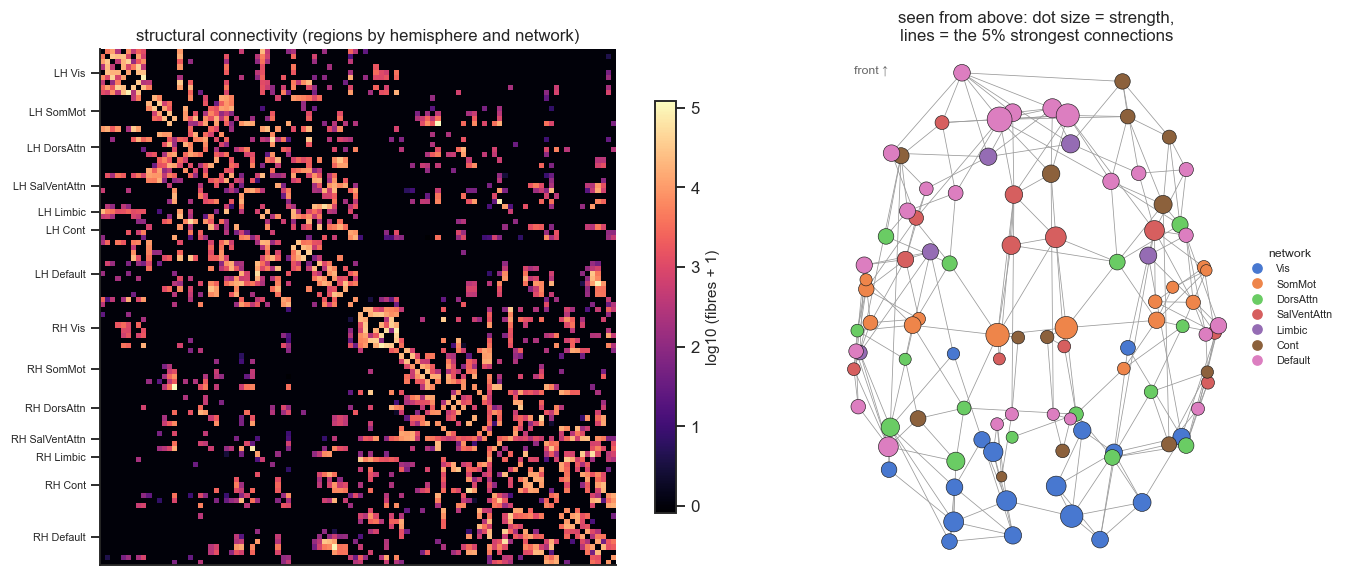

hub: LH_Default_PFC_5             strength 307k fibres (median region 109k)
hub: LH_SomMot_6                  strength 268k fibres (median region 109k)
hub: RH_Default_PFCdPFCm_2        strength 261k fibres (median region 109k)
hub: RH_Vis_8                     strength 247k fibres (median region 109k)
hub: RH_SomMot_8                  strength 246k fibres (median region 109k)


In [2]:
# @title Connectivity matrix, and the brain seen from above (dot size = strength)
strength = sc.sum(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw=dict(width_ratios=[1.15, 1]))
im = ax[0].imshow(np.log10(sc + 1), cmap="magma"); plt.colorbar(im, ax=ax[0], shrink=0.8, label="log10 (fibres + 1)")
edges_ = [0] + [k for k in range(1, 100) if net[k] != net[k - 1] or labels[k][10:12] != labels[k - 1][10:12]] + [100]
ax[0].set_xticks([]); ax[0].set_yticks((np.array(edges_[:-1]) + np.array(edges_[1:])) / 2 - 0.5,
                                       [f"{labels[k][10:12]} {net[k]}" for k in edges_[:-1]], fontsize=7)
ax[0].set_title("structural connectivity (regions by hemisphere and network)")
strong = sc >= np.quantile(sc[u], 0.95)                              # the 5% strongest connections
brain(ax[1], [NETCOL[n] for n in net], cmap=None, edges=strong, size=15 + 250 * strength / strength.max(),
      title="seen from above: dot size = strength,\nlines = the 5% strongest connections")
for n in NETS: ax[1].plot([], [], "o", c=NETCOL[n], label=n)
ax[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5), title="network", title_fontsize=8)
plt.tight_layout(); plt.show()
for k in np.argsort(-strength)[:5]:
    print(f"hub: {labels[k][10:]:28s} strength {strength[k] / 1000:.0f}k fibres (median region {np.median(strength) / 1000:.0f}k)")

Connections are dense within each hemisphere and sparse between them. The hubs (largest dots) sit in medial prefrontal,
somatomotor and visual cortex.

## 2. Wiring cost: most connections are short

> **Gist.** Axons cost space and energy: the probability of a connection, and the number of fibres, fall steeply with
> distance. A few long connections remain.

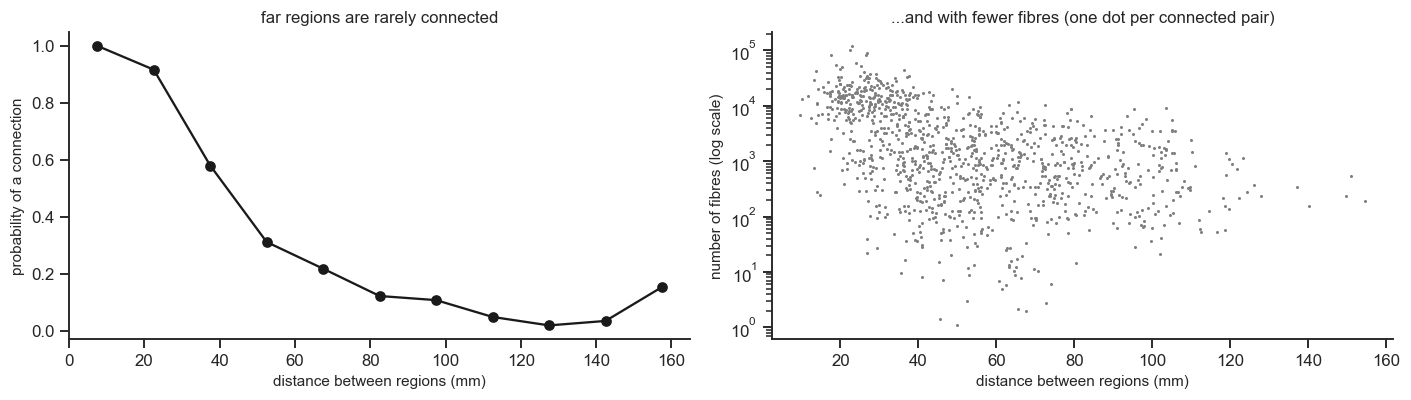

In [3]:
# @title Connection probability and number of fibres against distance
D = np.linalg.norm(xyz[:, None] - xyz[None], axis=-1)              # distance between region centres (mm)
d, w = D[u], sc[u]
bins = np.arange(0, 170, 15); mid = (bins[1:] + bins[:-1]) / 2
p_conn = [(w[(d >= a) & (d < b)] > 0).mean() for a, b in zip(bins[:-1], bins[1:])]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(mid, p_conn, "ko-"); ax[0].set(xlabel="distance between regions (mm)", ylabel="probability of a connection", title="far regions are rarely connected")
ax[1].semilogy(d[w > 0], w[w > 0], ".", ms=2, c="0.5")
ax[1].set(xlabel="distance between regions (mm)", ylabel="number of fibres (log scale)", title="...and with fewer fibres (one dot per connected pair)")
plt.tight_layout(); plt.show()

## 3. Segregation and integration: a small world of modules

> **Gist.** As in the slides: high **clustering** (my neighbours are neighbours of each other) and short **path
> length** (few steps between any two regions). We compare the brain with a randomly rewired copy that keeps the
> number of connections of every region.

<details><summary>Definitions (for the curious)</summary>

We keep the 40% strongest connections. *Clustering* of a region: of all pairs of its neighbours, the fraction that are
connected to each other (averaged over regions). *Path length*: the smallest number of connections between two regions
(averaged over all pairs). *Modules*: groups found by the Louvain algorithm, which maximises the number of connections
inside groups compared with chance.
</details>

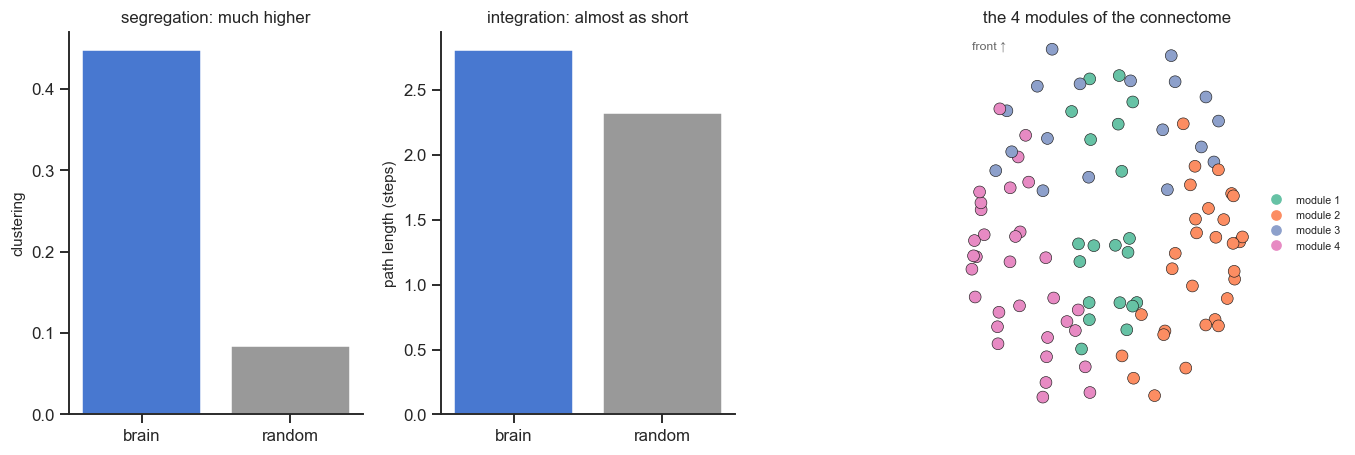

clustering: brain 0.45, random 0.08;  path length: brain 2.81, random 2.32 steps


In [4]:
# @title Clustering and path length: brain vs randomly rewired copy; modules of the connectome
A = (sc >= np.quantile(sc[u][sc[u] > 0], 0.6)).astype(int); np.fill_diagonal(A, 0)
Gb = nx.from_numpy_array(A)
Gr = Gb.copy(); nx.double_edge_swap(Gr, nswap=5 * Gb.number_of_edges(), max_tries=10**6, seed=1)   # same degrees, random wiring
C = [nx.average_clustering(g) for g in (Gb, Gr)]
L = [nx.average_shortest_path_length(g) for g in (Gb, Gr)]
modules = nx.community.louvain_communities(nx.from_numpy_array(np.log1p(sc)), seed=1)
module_of = np.zeros(100, int)
for k, m in enumerate(modules): module_of[list(m)] = k
MODCOL = plt.cm.Set2(np.arange(len(modules)))

fig, ax = plt.subplots(1, 3, figsize=(13, 4.3), gridspec_kw=dict(width_ratios=[0.6, 0.6, 1.2]))
ax[0].bar(["brain", "random"], C, color=["C0", "0.6"]); ax[0].set(ylabel="clustering", title="segregation: much higher")
ax[1].bar(["brain", "random"], L, color=["C0", "0.6"]); ax[1].set(ylabel="path length (steps)", title="integration: almost as short")
brain(ax[2], MODCOL[module_of], cmap=None, title=f"the {len(modules)} modules of the connectome")
for k in range(len(modules)): ax[2].plot([], [], "o", c=MODCOL[k], label=f"module {k + 1}")
ax[2].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()
print(f"clustering: brain {C[0]:.2f}, random {C[1]:.2f};  path length: brain {L[0]:.2f}, random {L[1]:.2f} steps")

Far more clustered than chance, yet any two regions are still about 3 steps apart: a small world. The modules follow
the anatomy: neighbouring regions end up in the same module.

## 4. What does a model need from the wiring?

> **Gist.** Build fake connectomes that keep **one** property of the real one, put each into the same Hopf model
> (NB10), and compare the model FC with the measured FC. If a fake works as well as the real one, the property it
> keeps is what matters.

* **random places:** the same list of fibre counts, given to random pairs of regions;
* **same lengths:** fibre counts exchanged only between connections of similar length (section 2).

<details><summary>Details (for the curious)</summary>

Hopf model with $a=-0.1$ and $G=2$ (the homogeneous best setting of NB13b), 2 × 20 minutes per connectome. Only the
tractography part is scrambled: the mirror connections between hemispheres added in NB10 are the same in every
connectome. "Same lengths": the pairs are split into 20 distance bins and the fibre counts are permuted within each bin.
Three fakes of each kind (dots).
</details>

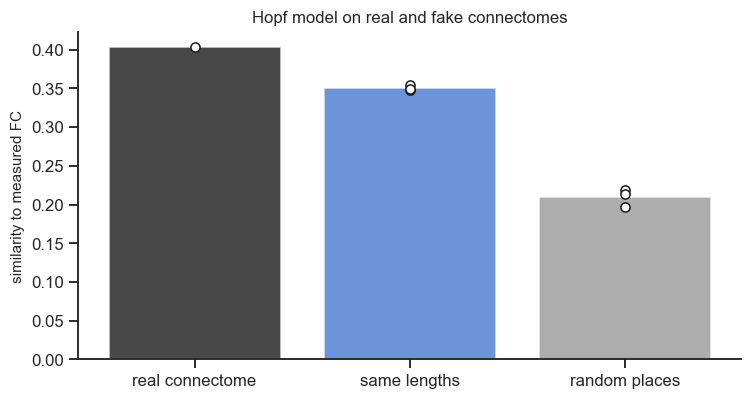

real connectome: 0.40  same lengths: 0.35  random places: 0.21


In [5]:
# @title Fake connectomes in the same Hopf model (a few seconds)
pairs = connectome.homotopic_pairs("schaefer100", labels)
def as_model_input(M):                                             # scaling and mirror links exactly as in NB10
    M = M / M.sum(1).max()
    for k, j in pairs: M[k, j] += 0.5; M[j, k] += 0.5
    return M

def fit(M, G=2.0, a=-0.1):
    F = np.mean([np.corrcoef(wholebrain.hopf_network(as_model_input(M), G, a=a, T=1200, TR=2.0, seed=s)[1].T) for s in range(2)], 0)
    return similarity(F, fc)

def from_upper(w):
    M = np.zeros((100, 100)); M[u] = w; return M + M.T

def random_places(M, rng):
    return from_upper(rng.permutation(M[u]))

def same_lengths(M, rng, n_bins=20):
    w = M[u].copy(); edges = np.quantile(d, np.linspace(0, 1, n_bins + 1))
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (d >= lo) & (d <= hi); w[m] = rng.permutation(w[m])
    return from_upper(w)

rng = np.random.default_rng(0)
scores = {"real connectome": [fit(sc)],
          "same lengths": [fit(same_lengths(sc, rng)) for _ in range(3)],
          "random places": [fit(random_places(sc, rng)) for _ in range(3)]}
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (name, s) in enumerate(scores.items()):
    ax.bar(k, np.mean(s), color=["k", "C0", "0.6"][k], alpha=0.8)
    ax.plot(np.full(len(s), k), s, "o", c="w", mec="k", ms=6)
ax.set_xticks(range(3), list(scores)); ax.set(ylabel="similarity to measured FC", title="Hopf model on real and fake connectomes")
plt.tight_layout(); plt.show()
print("  ".join(f"{k}: {np.mean(v):.2f}" for k, v in scores.items()))

Connecting the wrong pairs of regions costs about half of the fit. Keeping only the **length** of each connection
recovers most of it: much of what the connectome gives to FC comes from **geometry**, nearby regions being wired and
therefore correlated (Roberts et al. 2016; Pang et al. 2023). The rest needs the specific pairs.

## 5. Cortical gradients: from sensation to abstraction

> **Gist.** As in the slides, many properties of the cortex change smoothly from sensory to association areas. We
> compute the **principal gradient** of the measured FC, and compare it with an anatomical map measured without any
> activity: intracortical **myelin** (MRI T1w/T2w ratio; Glasser & Van Essen 2011).

<details><summary>How the FC gradient is computed (for the curious)</summary>

Keep, for each region, its 10% strongest FC values; compute the cosine similarity between the FC patterns of every
pair of regions; the gradients are the leading components of a **diffusion map** of this similarity (as in the
BrainSpace toolbox, Vos de Wael et al. 2020): a nonlinear version of principal component analysis. Myelin here is the
myelin **inside the grey matter**, a marker of the type of cortical area, not the myelin of the white-matter fibres.
</details>

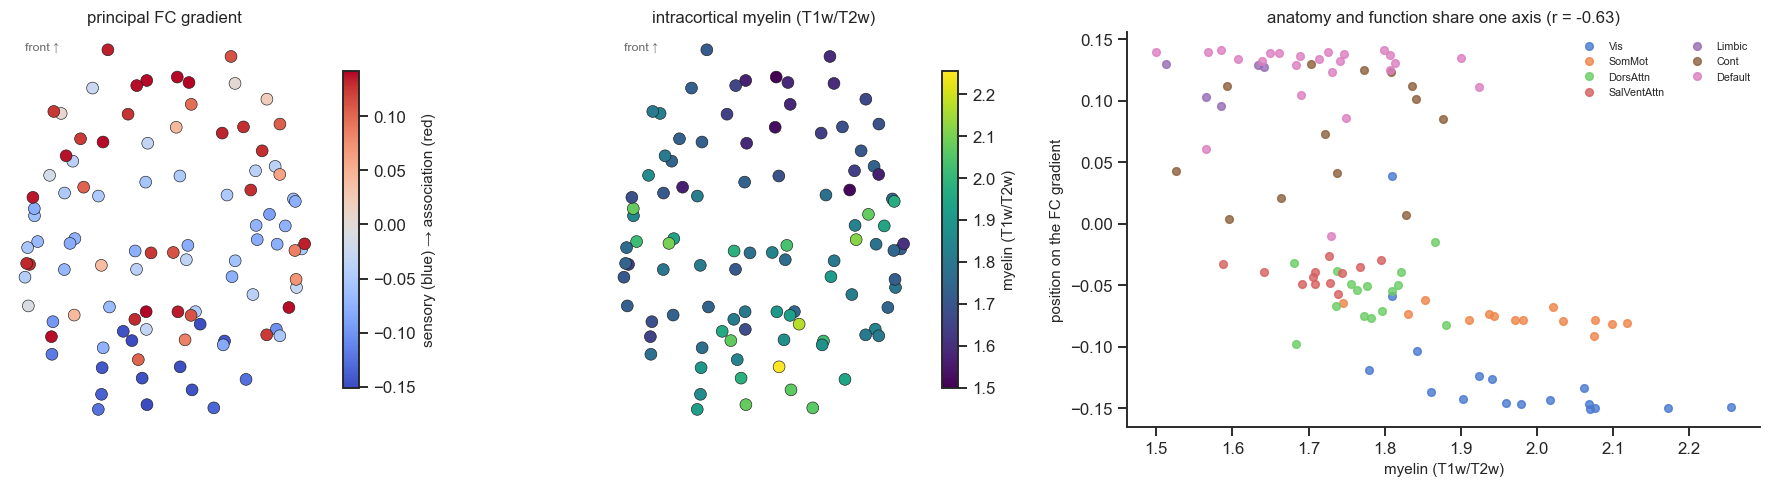

In [6]:
# @title Principal FC gradient and intracortical myelin, on the brain and against each other
def fc_gradients(M, keep=0.1, alpha=0.5, n=2):
    M = M.copy(); np.fill_diagonal(M, 0)
    X = np.where(M >= np.quantile(M, 1 - keep, axis=1, keepdims=True), M, 0)       # keep each row's strongest 10%
    X = X / np.linalg.norm(X, axis=1, keepdims=True); K = np.clip(X @ X.T, 0, None)   # cosine similarity
    dg = K.sum(1); P = K / np.outer(dg**alpha, dg**alpha); P /= P.sum(1, keepdims=True)  # diffusion operator
    ev, vec = np.linalg.eig(P); o = np.argsort(-ev.real)
    return vec.real[:, o[1:n + 1]]

grad = fc_gradients(fc)[:, 0]
grad = grad * np.sign(grad[net == "Default"].mean())               # convention: default mode network at the top
myelin = np.loadtxt("../data/connectome/myelin_t1wt2w_schaefer_100.csv", comments="#")   # one value per region
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.3]))
s_ = brain(ax[0], grad, cmap="coolwarm", title="principal FC gradient")
plt.colorbar(s_, ax=ax[0], shrink=0.8, label="sensory (blue) → association (red)")
s_ = brain(ax[1], myelin, cmap="viridis", title="intracortical myelin (T1w/T2w)")
plt.colorbar(s_, ax=ax[1], shrink=0.8, label="myelin (T1w/T2w)")
for n in NETS:
    ax[2].plot(myelin[net == n], grad[net == n], "o", c=NETCOL[n], ms=5, alpha=0.8, label=n)
ax[2].set(xlabel="myelin (T1w/T2w)", ylabel="position on the FC gradient",
          title=f"anatomy and function share one axis (r = {np.corrcoef(myelin, grad)[0, 1]:.2f})")
ax[2].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

Visual and somatomotor regions sit at the sensory end of the FC gradient and are heavily myelinated; default mode and
limbic regions sit at the association end with little myelin. A functional map and an anatomical map line up. In
**NB13b** we use the myelin map to make the regions of the model different from each other.

## 6. Take-home

* The connectome has **hubs**, mostly **short** connections, and a **small-world**, **modular** organisation.
* In a model, **who is connected to whom** matters for FC, and a large part of it is set by geometry (connection length).
* The cortex is organised along a sensory → association **gradient**; anatomy (myelin) and function (FC) share it.
* **Next (NB13b):** let the myelin map set how each region behaves.

### Homework
*To do at home, after the class. These exercises need a few lines of your own code.*
1. **Rich club.** Do hubs connect preferentially to each other? Take the 12 regions with the highest strength and compare
   the density of connections among them with the density of the whole network (van den Heuvel & Sporns 2011).
2. **Structure vs function.** Correlate `np.log1p(sc)` with the measured FC over all pairs. Is the correlation higher
   for short or for long connections?
3. **Distance alone.** Build a connectome from distance only, $W_{ij}=e^{-D_{ij}/\lambda}$ with $\lambda=20$ mm, and
   use `fit` from section 4. Try $\lambda=10$ and $30$ mm.
4. **Same degrees.** Write a fake connectome in which every region keeps its number of connections but they go to
   random partners (hint: `nx.double_edge_swap`, as in section 3). How does it compare with "random places"?
5. **Myelin and hubs.** Are hubs (high strength) strongly or weakly myelinated?

### References
* Sporns O (2011). *Networks of the Brain*. MIT Press. Bullmore E, Sporns O (2012). The economy of brain network
  organization. *Nat Rev Neurosci* 13:336–349.
* Watts DJ, Strogatz SH (1998). Collective dynamics of 'small-world' networks. *Nature* 393:440–442.
* van den Heuvel MP, Sporns O (2011). Rich-club organization of the human connectome. *J Neurosci* 31:15775–15786.
* Roberts JA et al. (2016). The contribution of geometry to the human connectome. *NeuroImage* 124:379–393.
* Pang JC et al. (2023). Geometric constraints on human brain function. *Nature* 618:566–574.
* Margulies DS et al. (2016). Situating the default-mode network along a principal gradient of macroscale cortical
  organization. *PNAS* 113:12574–12579.
* Huntenburg JM, Bazin P-L, Margulies DS (2018). Large-scale gradients in human cortical organization. *Trends Cogn Sci*
  22:21–31.
* Vos de Wael R et al. (2020). BrainSpace: a toolbox for the analysis of macroscale gradients in neuroimaging and
  connectomics datasets. *Commun Biol* 3:103.
* Glasser MF, Van Essen DC (2011). Mapping human cortical areas in vivo based on myelin content as revealed by T1- and
  T2-weighted MRI. *J Neurosci* 31:11597–11616.
* Yeo BTT et al. (2011). The organization of the human cerebral cortex estimated by intrinsic functional connectivity.
  *J Neurophysiol* 106:1125–1165. Schaefer A et al. (2018). *Cereb Cortex* 28:3095–3114.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700.